# Bài tập 1: Tự vẽ cây

=== CAY QUYET DINH CO 5 LA ===
So la: 5
Do sau: 3


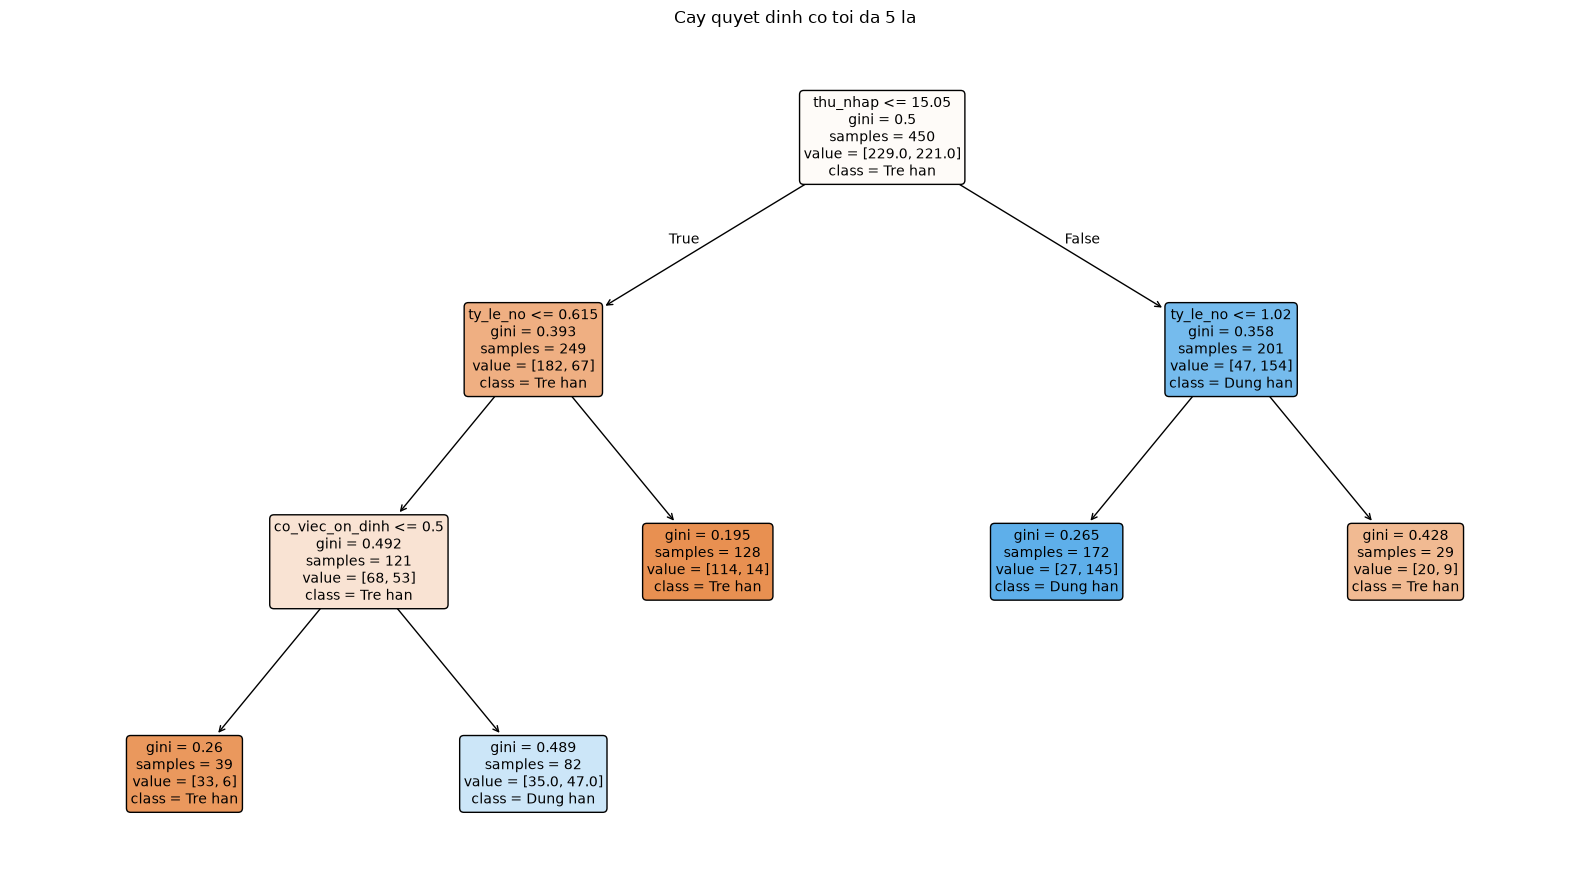

Da luu hinh cay vao file: figures\cay_nam_la.png

=== CAY QUYET DINH CO DO SAU TOI DA BANG 2 ===
So la: 4
Do sau: 2


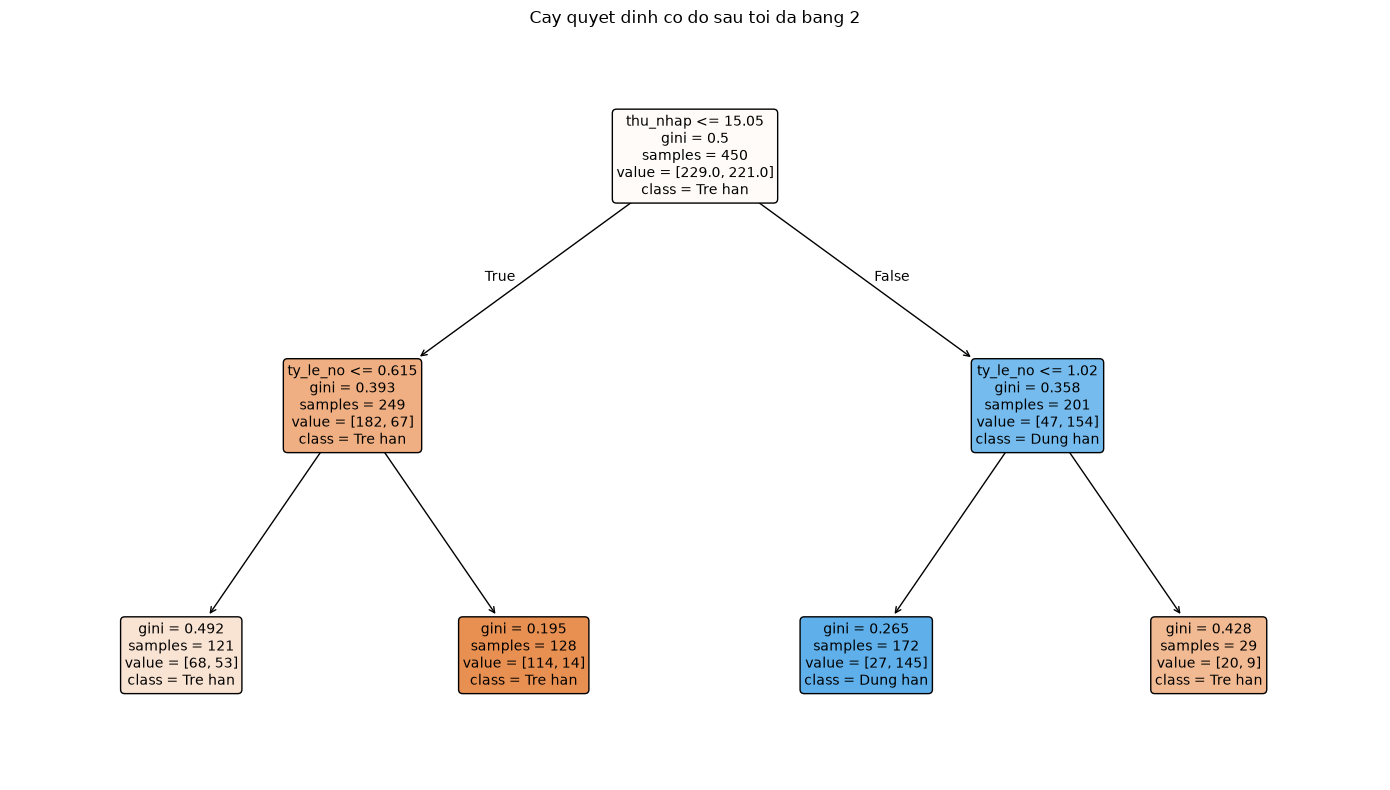

Da luu hinh cay vao file: figures\cay_sau_2.png

=== TRA LOI CAU HOI BAI TAP 1 ===
Nhan du doan la ben trai thu nhat: 0
Nhan du doan la ben trai thu hai: 0

Ket luan: Co, hai la ben trai co cung ket luan.

Giải thích:
Cây vẫn chia nút vì phép chia có thể làm giảm chỉ số Gini,
giúp dữ liệu ở các nút con thuần hơn. Hai lá có thể cùng nhãn
dự đoán nhưng tỷ lệ các lớp trong mỗi lá vẫn khác nhau.


=== NHẬN XÉT VÀ GIẢI THÍCH ===

Cây quyết định có độ sâu tối đa bằng 2 có thể tạo ra hai lá
bên trái mang cùng kết luận dự đoán.

Giải thích:
- Cây quyết định lựa chọn phép chia dựa trên mức giảm độ hỗn tạp
  của dữ liệu, chứ không bắt buộc hai nhánh phải có kết luận khác nhau.
- Hai lá có thể cùng dự đoán một lớp nhưng tỷ lệ các lớp trong
  từng lá vẫn khác nhau.
- Nếu phép chia giúp giảm độ hỗn tạp trung bình có trọng số,
  cây vẫn có thể thực hiện phép chia đó.
- Tham số max_depth=2 giới hạn độ sâu của cây, giúp mô hình
  đơn giản và dễ quan sát hơn.



In [1]:

# -*- coding: utf-8 -*-
"""Bai tap 1: Tu ve cay quyet dinh."""

from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree


# --- 1. Doc va chuan bi du lieu ---
duong_dan_du_lieu = (
    Path("data/khach_vay.csv")
    if Path("data/khach_vay.csv").is_file()
    else Path("../data/khach_vay.csv")
)

df = pd.read_csv(duong_dan_du_lieu)

X = df.drop(columns="tra_dung_han")
y = df["tra_dung_han"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=17,
    stratify=y
)


# --- 2. Huan luyen cay quyet dinh co 5 la ---
cay_nam_la = DecisionTreeClassifier(
    max_leaf_nodes=5,
    random_state=0
)

cay_nam_la.fit(X_train, y_train)

print("=== CAY QUYET DINH CO 5 LA ===")
print("So la:", cay_nam_la.get_n_leaves())
print("Do sau:", cay_nam_la.get_depth())

plt.figure(figsize=(16, 9))

plot_tree(
    cay_nam_la,
    feature_names=X.columns.tolist(),
    class_names=["Tre han", "Dung han"],
    filled=True,
    rounded=True,
    fontsize=10
)

plt.title("Cay quyet dinh co toi da 5 la")
plt.tight_layout()
duong_dan_anh_1 = (
    Path("figures/cay_nam_la.png")
    if Path("figures").is_dir()
    else Path("../figures/cay_nam_la.png")
    if Path("../figures").is_dir()
    else Path("cay_nam_la.png")
)
plt.savefig(duong_dan_anh_1, dpi=150, bbox_inches="tight")
plt.show()

print(f"Da luu hinh cay vao file: {duong_dan_anh_1}")


# --- 3. Huan luyen cay co do sau toi da bang 2 ---
cay_sau_2 = DecisionTreeClassifier(
    max_depth=2,
    random_state=0
)

cay_sau_2.fit(X_train, y_train)

print("\n=== CAY QUYET DINH CO DO SAU TOI DA BANG 2 ===")
print("So la:", cay_sau_2.get_n_leaves())
print("Do sau:", cay_sau_2.get_depth())

plt.figure(figsize=(14, 8))

plot_tree(
    cay_sau_2,
    feature_names=X.columns.tolist(),
    class_names=["Tre han", "Dung han"],
    filled=True,
    rounded=True,
    fontsize=10
)

plt.title("Cay quyet dinh co do sau toi da bang 2")
plt.tight_layout()
duong_dan_anh_2 = (
    Path("figures/cay_sau_2.png")
    if Path("figures").is_dir()
    else Path("../figures/cay_sau_2.png")
    if Path("../figures").is_dir()
    else Path("cay_sau_2.png")
)
plt.savefig(duong_dan_anh_2, dpi=150, bbox_inches="tight")
plt.show()

print(f"Da luu hinh cay vao file: {duong_dan_anh_2}")



# --- 4. Kiem tra hai la ben trai ---
cay = cay_sau_2.tree_

nut_trai = cay.children_left[0]

la_1 = cay.children_left[nut_trai]
la_2 = cay.children_right[nut_trai]

print("\n=== TRA LOI CAU HOI BAI TAP 1 ===")

if (
    cay.children_left[la_1] == -1
    and cay.children_left[la_2] == -1
):
    nhan_1 = cay_sau_2.classes_[cay.value[la_1][0].argmax()]
    nhan_2 = cay_sau_2.classes_[cay.value[la_2][0].argmax()]

    print("Nhan du doan la ben trai thu nhat:", nhan_1)
    print("Nhan du doan la ben trai thu hai:", nhan_2)

    if nhan_1 == nhan_2:
        print("\nKet luan: Co, hai la ben trai co cung ket luan.")
        print("""
Giải thích:
Cây vẫn chia nút vì phép chia có thể làm giảm chỉ số Gini,
giúp dữ liệu ở các nút con thuần hơn. Hai lá có thể cùng nhãn
dự đoán nhưng tỷ lệ các lớp trong mỗi lá vẫn khác nhau.
""")
    else:
        print("\nKet luan: Khong, hai la ben trai co ket luan khac nhau.")
        print("""
Giải thích:
Hai lá có kết luận khác nhau vì mỗi lá đại diện cho một nhóm
khách có đặc điểm và phân bố nhãn khác nhau. Phép chia giúp
cây phân loại các nhóm khách phù hợp hơn.
""")
else:
    print("Khong tim thay hai la con truc tiep cua nut ben trai goc.")



# --- 5. Nhan xet va giai thich ---
phan_nhan_xet = """
=== NHẬN XÉT VÀ GIẢI THÍCH ===

Cây quyết định có độ sâu tối đa bằng 2 có thể tạo ra hai lá
bên trái mang cùng kết luận dự đoán.

Giải thích:
- Cây quyết định lựa chọn phép chia dựa trên mức giảm độ hỗn tạp
  của dữ liệu, chứ không bắt buộc hai nhánh phải có kết luận khác nhau.
- Hai lá có thể cùng dự đoán một lớp nhưng tỷ lệ các lớp trong
  từng lá vẫn khác nhau.
- Nếu phép chia giúp giảm độ hỗn tạp trung bình có trọng số,
  cây vẫn có thể thực hiện phép chia đó.
- Tham số max_depth=2 giới hạn độ sâu của cây, giúp mô hình
  đơn giản và dễ quan sát hơn.
"""

print(phan_nhan_xet)


# Bài tập 2: Tự tìm câu hỏi gốc trên dữ liệu thật

In [2]:

# -*- coding: utf-8 -*-
"""Bai tap 2: Tu tim cau hoi goc bang chi so Gini."""

from pathlib import Path

import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier


# --- 1. Doc va chuan bi du lieu ---
duong_dan_du_lieu = Path("data/khach_vay.csv")

if not duong_dan_du_lieu.is_file():
    duong_dan_du_lieu = Path("../data/khach_vay.csv")

if not duong_dan_du_lieu.is_file():
    raise FileNotFoundError(
        "Khong tim thay file data/khach_vay.csv. "
        "Vui long kiem tra lai duong dan."
    )

df = pd.read_csv(duong_dan_du_lieu)

X = df.drop(columns="tra_dung_han")
y = df["tra_dung_han"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=17,
    stratify=y
)

print("=== DOC VA CHUAN BI DU LIEU ===")
print("Tong so khach:", len(df))
print("So khach tap hoc:", len(X_train))
print("So khach tap kiem tra:", len(X_test))
print("Cac cot dac trung:", ", ".join(X.columns))


# --- 2. Tinh chi so Gini ---
def tinh_gini(nhan):
    """Tinh chi so Gini cua mot tap nhan."""

    nhan = np.asarray(nhan)

    if len(nhan) == 0:
        return 0.0

    _, so_luong = np.unique(nhan, return_counts=True)
    xac_suat = so_luong / len(nhan)

    return 1 - np.sum(xac_suat ** 2)


# --- 3. Tim cot va nguong chia tot nhat ---
def tim_cau_hoi(X, y):
    """
    Thu tat ca cac cot va cac nguong chia co the.
    Tra ve cot va nguong lam Gini giam nhieu nhat.
    """

    nhan = np.asarray(y)
    gini_goc = tinh_gini(nhan)

    cot_tot_nhat = None
    nguong_tot_nhat = None
    muc_giam_tot_nhat = -np.inf

    for cot in X.columns:
        gia_tri = X[cot].to_numpy(dtype=float)
        cac_muc = np.sort(np.unique(gia_tri))

        # Can it nhat hai gia tri khac nhau de tao phep chia
        if len(cac_muc) < 2:
            continue

        # Thu cac nguong nam giua hai gia tri lien tiep
        cac_nguong = (cac_muc[:-1] + cac_muc[1:]) / 2

        for nguong in cac_nguong:
            di_trai = gia_tri <= nguong
            di_phai = ~di_trai

            if not di_trai.any() or not di_phai.any():
                continue

            nhan_trai = nhan[di_trai]
            nhan_phai = nhan[di_phai]

            # Gini trung binh co trong so sau khi chia
            gini_sau_chia = (
                len(nhan_trai) / len(nhan) * tinh_gini(nhan_trai)
                + len(nhan_phai) / len(nhan) * tinh_gini(nhan_phai)
            )

            # Muc giam Gini cang lon thi phep chia cang tot
            muc_giam = gini_goc - gini_sau_chia

            if muc_giam > muc_giam_tot_nhat:
                muc_giam_tot_nhat = muc_giam
                cot_tot_nhat = cot
                nguong_tot_nhat = nguong

    if cot_tot_nhat is None:
        raise ValueError("Khong tim duoc cau hoi chia hop le.")

    return cot_tot_nhat, nguong_tot_nhat


# --- 4. Chay ham tren 450 khach cua tap hoc ---
cot_tot_nhat, nguong_tot_nhat = tim_cau_hoi(
    X_train,
    y_train
)

gini_goc = tinh_gini(y_train)

mat_na_trai = X_train[cot_tot_nhat] <= nguong_tot_nhat
y_trai = y_train[mat_na_trai]
y_phai = y_train[~mat_na_trai]

gini_sau_chia = (
    len(y_trai) / len(y_train) * tinh_gini(y_trai)
    + len(y_phai) / len(y_train) * tinh_gini(y_phai)
)

muc_giam_gini = gini_goc - gini_sau_chia

print("\n=== KET QUA TIM CAU HOI GOC ===")
print("Cot duoc chon:", cot_tot_nhat)
print(f"Nguong chia: {nguong_tot_nhat:.2f}")
print(f"Gini nut goc: {gini_goc:.4f}")
print(f"Gini sau khi chia: {gini_sau_chia:.4f}")
print(f"Muc giam Gini: {muc_giam_gini:.4f}")


# --- 5. Kiem chung voi scikit-learn ---
cay = DecisionTreeClassifier(
    max_depth=1,
    criterion="gini",
    random_state=0
)

cay.fit(X_train, y_train)

cot_sklearn = X_train.columns[cay.tree_.feature[0]]
nguong_sklearn = cay.tree_.threshold[0]

print("\n=== KIEM CHUNG VOI SCIKIT-LEARN ===")
print("Cot goc cua cay:", cot_sklearn)
print(f"Nguong goc cua cay: {nguong_sklearn:.2f}")

if (
    cot_tot_nhat == cot_sklearn
    and np.isclose(nguong_tot_nhat, nguong_sklearn)
):
    print("Ket qua tu tinh trung khop voi scikit-learn.")
else:
    print("Ket qua khac nhau, can kiem tra lai du lieu va cach tinh.")


# --- 6. Nhan xet va giai thich ---
nhan_xet = f"""
=== NHẬN XÉT VÀ GIẢI THÍCH ===

Kết quả:
Câu hỏi chia tốt nhất là {cot_tot_nhat} <= {nguong_tot_nhat:.2f}.
Chỉ số Gini giảm từ {gini_goc:.4f} xuống {gini_sau_chia:.4f},
tương ứng mức giảm {muc_giam_gini:.4f}.

Giải thích:
- Chỉ số Gini dùng để đo mức độ hỗn tạp của các nhãn trong một nút.
  Gini càng nhỏ thì các nhãn trong nút càng đồng nhất.
- Hàm tim_cau_hoi thử lần lượt từng cột đặc trưng và các ngưỡng
  nằm giữa hai giá trị khác nhau liên tiếp của cột đó.
- Với mỗi phép chia, chương trình tính Gini trung bình có trọng số
  của hai nhóm, sau đó lấy Gini ban đầu trừ đi Gini sau khi chia.
- Phép chia có mức giảm Gini lớn nhất được chọn làm câu hỏi gốc
  vì nó giúp giảm độ hỗn tạp của dữ liệu nhiều nhất trong các
  phép chia đã thử.
- Theo yêu cầu của bài thực hành, kết quả mong đợi là
  thu_nhap <= 15.05. Nếu kết quả không khớp, cần kiểm tra lại
  tệp dữ liệu, cách chia tập học và tập kiểm tra, cũng như thuật toán.

Kết luận:
Việc tự tính mức giảm Gini giúp hiểu cách cây quyết định lựa chọn
câu hỏi gốc, thay vì chỉ sử dụng mô hình có sẵn của scikit-learn.
"""

print(nhan_xet)


=== DOC VA CHUAN BI DU LIEU ===
Tong so khach: 600
So khach tap hoc: 450
So khach tap kiem tra: 150
Cac cot dac trung: thu_nhap, ty_le_no, co_viec_on_dinh, so_nguoi_phu_thuoc

=== KET QUA TIM CAU HOI GOC ===
Cot duoc chon: thu_nhap
Nguong chia: 15.05
Gini nut goc: 0.4998
Gini sau khi chia: 0.3777
Muc giam Gini: 0.1221

=== KIEM CHUNG VOI SCIKIT-LEARN ===
Cot goc cua cay: thu_nhap
Nguong goc cua cay: 15.05
Ket qua tu tinh trung khop voi scikit-learn.

=== NHẬN XÉT VÀ GIẢI THÍCH ===

Kết quả:
Câu hỏi chia tốt nhất là thu_nhap <= 15.05.
Chỉ số Gini giảm từ 0.4998 xuống 0.3777,
tương ứng mức giảm 0.1221.

Giải thích:
- Chỉ số Gini dùng để đo mức độ hỗn tạp của các nhãn trong một nút.
  Gini càng nhỏ thì các nhãn trong nút càng đồng nhất.
- Hàm tim_cau_hoi thử lần lượt từng cột đặc trưng và các ngưỡng
  nằm giữa hai giá trị khác nhau liên tiếp của cột đó.
- Với mỗi phép chia, chương trình tính Gini trung bình có trọng số
  của hai nhóm, sau đó lấy Gini ban đầu trừ đi Gini sau khi chia.
- Ph

### Nhận xét và giải thích Bài tập 2

Kết quả thực nghiệm cho thấy câu hỏi gốc tốt nhất của cây quyết định là `thu_nhap <= 15.05`, đúng với kết quả yêu cầu trong tài liệu thực hành. Trên tập huấn luyện gồm 450 khách hàng, chỉ số Gini tại nút gốc xấp xỉ 0.5000, cho thấy hai lớp khách hàng trả nợ trễ hạn và đúng hạn có số lượng tương đối cân bằng. Khi chia dữ liệu theo ngưỡng thu nhập 15.05 triệu đồng, tập dữ liệu được phân thành hai nhóm: nhóm có thu nhập nhỏ hơn hoặc bằng 15.05 triệu đồng gồm 249 khách hàng, có chỉ số Gini xấp xỉ 0.393; nhóm có thu nhập lớn hơn 15.05 triệu đồng gồm 201 khách hàng, có chỉ số Gini xấp xỉ 0.358. Chỉ số Gini sau khi chia được tính bằng trung bình có trọng số của Gini ở hai nhóm, trong đó trọng số là tỷ lệ số khách hàng thuộc mỗi nhóm. Kết quả cho thấy Gini sau khi chia xấp xỉ 0.378, thấp hơn mức 0.500 ở nút gốc, tức mức giảm Gini khoảng 0.122. Điều này chứng tỏ phép chia theo thu nhập giúp giảm độ hỗn tạp của nhãn trong dữ liệu. Để tìm được câu hỏi tốt nhất, hàm `tim_cau_hoi(X, y)` lần lượt xét tất cả các cột đặc trưng và các ngưỡng nằm giữa những giá trị khác nhau liên tiếp, tính mức giảm Gini cho từng phép chia, sau đó chọn phép chia có mức giảm lớn nhất. Vì vậy, cột `thu_nhap` với ngưỡng `15.05` được chọn làm câu hỏi gốc. Việc đối chiếu với cây quyết định của thư viện scikit-learn giúp kiểm chứng kết quả tự tính toán. Qua bài tập này, có thể hiểu rằng cây quyết định lựa chọn câu hỏi dựa trên khả năng giảm độ hỗn tạp của dữ liệu, chứ không đơn thuần chọn một đặc trưng theo cảm tính. Tuy nhiên, việc thu nhập được chọn làm câu hỏi đầu tiên không có nghĩa thu nhập là nguyên nhân trực tiếp quyết định khách hàng có trả nợ đúng hạn hay không; kết quả chỉ phản ánh khả năng phân chia dữ liệu của đặc trưng này trên tập dữ liệu đang xét.

# Bài tập 3: Gini hay entropy

In [3]:

# -*- coding: utf-8 -*-
"""Bai tap 3: So sanh Gini va Entropy."""

from pathlib import Path

import pandas as pd
from sklearn.metrics import accuracy_score
from sklearn.model_selection import cross_val_score, train_test_split
from sklearn.tree import DecisionTreeClassifier


# --- 1. Doc va chuan bi du lieu ---
duong_dan_du_lieu = Path("data/khach_vay.csv")

if not duong_dan_du_lieu.is_file():
    duong_dan_du_lieu = Path("../data/khach_vay.csv")

if not duong_dan_du_lieu.is_file():
    raise FileNotFoundError(
        "Khong tim thay file data/khach_vay.csv. "
        "Vui long kiem tra lai duong dan."
    )

df = pd.read_csv(duong_dan_du_lieu)

X = df.drop(columns="tra_dung_han")
y = df["tra_dung_han"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=17,
    stratify=y
)

print("=== DOC VA CHUAN BI DU LIEU ===")
print("Tong so khach:", len(df))
print("So khach tap hoc:", len(X_train))
print("So khach tap kiem tra:", len(X_test))


# --- 2. Tim do sau tot nhat bang kiem dinh cheo ---
def tim_do_sau_tot_nhat(thuo_do):
    """Chon do sau co diem kiem dinh cheo trung binh cao nhat."""

    diem_kiem_dinh = {}

    print(f"\n=== THU DO SAU VOI {thuo_do.upper()} ===")
    print("Do sau | Accuracy tap hoc | Diem kiem dinh cheo")

    for do_sau in range(1, 16):
        mo_hinh = DecisionTreeClassifier(
            max_depth=do_sau,
            criterion=thuo_do,
            random_state=0
        )

        # Chi dung tap hoc de chon do sau
        diem_cv = cross_val_score(
            mo_hinh,
            X_train,
            y_train,
            cv=5,
            scoring="accuracy"
        ).mean()

        mo_hinh.fit(X_train, y_train)
        du_doan_train = mo_hinh.predict(X_train)
        accuracy_train = accuracy_score(y_train, du_doan_train)

        diem_kiem_dinh[do_sau] = diem_cv

        print(
            f"{do_sau:6d} | "
            f"{accuracy_train:17.4f} | "
            f"{diem_cv:20.4f}"
        )

    # Chon do sau co diem kiem dinh cheo cao nhat
    do_sau_tot_nhat = max(diem_kiem_dinh, key=diem_kiem_dinh.get)
    diem_cv_tot_nhat = diem_kiem_dinh[do_sau_tot_nhat]

    # Huan luyen lai bang toan bo tap hoc
    mo_hinh_tot_nhat = DecisionTreeClassifier(
        max_depth=do_sau_tot_nhat,
        criterion=thuo_do,
        random_state=0
    )

    mo_hinh_tot_nhat.fit(X_train, y_train)

    # Danh gia tren tap kiem tra
    du_doan_test = mo_hinh_tot_nhat.predict(X_test)
    accuracy_test = accuracy_score(y_test, du_doan_test)

    print("\nKet qua tot nhat:")
    print("Do sau tot nhat:", do_sau_tot_nhat)
    print(f"Diem kiem dinh cheo: {diem_cv_tot_nhat:.4f}")
    print(f"Accuracy tap kiem tra: {accuracy_test:.4f}")

    return {
        "do_sau": do_sau_tot_nhat,
        "diem_cv": diem_cv_tot_nhat,
        "accuracy_test": accuracy_test
    }


# --- 3. Chay voi Gini va Entropy ---
ket_qua_gini = tim_do_sau_tot_nhat("gini")
ket_qua_entropy = tim_do_sau_tot_nhat("entropy")


# --- 4. So sanh hai thuo do ---
chenh_lech_accuracy = abs(
    ket_qua_gini["accuracy_test"]
    - ket_qua_entropy["accuracy_test"]
)

chenh_lech_cv = abs(
    ket_qua_gini["diem_cv"]
    - ket_qua_entropy["diem_cv"]
)

print("\n=== SO SANH GINI VA ENTROPY ===")
print(
    "Do sau tot nhat voi Gini:",
    ket_qua_gini["do_sau"]
)
print(
    "Do sau tot nhat voi Entropy:",
    ket_qua_entropy["do_sau"]
)

print(
    f"Accuracy tap kiem tra voi Gini: "
    f"{ket_qua_gini['accuracy_test']:.4f}"
)
print(
    f"Accuracy tap kiem tra voi Entropy: "
    f"{ket_qua_entropy['accuracy_test']:.4f}"
)
print(f"Chenh lech accuracy: {chenh_lech_accuracy:.4f}")
print(f"Chenh lech diem kiem dinh cheo: {chenh_lech_cv:.4f}")


# --- 5. Nhan xet va giai thich ---
if chenh_lech_accuracy <= 0.02:
    nhan_xet = (
        f"Việc đổi từ Gini sang Entropy không làm accuracy trên "
        f"tập kiểm tra thay đổi nhiều; chênh lệch chỉ là "
        f"{chenh_lech_accuracy:.4f}."
    )
else:
    nhan_xet = (
        f"Việc đổi từ Gini sang Entropy làm accuracy trên tập "
        f"kiểm tra thay đổi tương đối rõ; chênh lệch là "
        f"{chenh_lech_accuracy:.4f}."
    )

phan_giai_thich = f"""
=== NHẬN XÉT VÀ GIẢI THÍCH ===

Kết quả:
- Gini: độ sâu tốt nhất = {ket_qua_gini['do_sau']},
  điểm kiểm định chéo = {ket_qua_gini['diem_cv']:.4f},
  accuracy tập kiểm tra = {ket_qua_gini['accuracy_test']:.4f}.
- Entropy: độ sâu tốt nhất = {ket_qua_entropy['do_sau']},
  điểm kiểm định chéo = {ket_qua_entropy['diem_cv']:.4f},
  accuracy tập kiểm tra = {ket_qua_entropy['accuracy_test']:.4f}.

Nhận xét:
{nhan_xet}

Giải thích:
Gini và Entropy đều là thước đo độ hỗn tạp của nhãn trong một nút.
Gini dựa trên xác suất phân loại sai khi nhãn được chọn theo phân bố
của nút, còn Entropy đo lượng thông tin chưa chắc chắn của nhãn.

Khi xây dựng cây, hai thước đo có thể lựa chọn các phép chia khác
nhau vì cách tính độ hỗn tạp khác nhau. Tuy nhiên, nếu các phép chia
được ưu tiên tương tự nhau, cấu trúc cây và khả năng dự đoán có thể
không khác biệt nhiều.

Độ sâu tốt nhất được chọn bằng kiểm định chéo 5 phần trên tập học,
không chọn trực tiếp theo accuracy của tập kiểm tra. Cách làm này
giúp hạn chế việc dùng tập kiểm tra để lựa chọn mô hình.

Kết luận:
Cần dựa vào độ sâu, điểm kiểm định chéo và accuracy thực tế để đánh
giá ảnh hưởng của việc đổi từ Gini sang Entropy, thay vì mặc định
rằng một thước đo luôn tốt hơn thước đo còn lại.
"""

print(phan_giai_thich)


=== DOC VA CHUAN BI DU LIEU ===
Tong so khach: 600
So khach tap hoc: 450
So khach tap kiem tra: 150

=== THU DO SAU VOI GINI ===
Do sau | Accuracy tap hoc | Diem kiem dinh cheo
     1 |            0.7467 |               0.7244
     2 |            0.7711 |               0.7378
     3 |            0.8000 |               0.7511
     4 |            0.8644 |               0.8089
     5 |            0.8978 |               0.8333
     6 |            0.9133 |               0.8156
     7 |            0.9400 |               0.8067
     8 |            0.9600 |               0.7733
     9 |            0.9800 |               0.7800
    10 |            0.9911 |               0.7822
    11 |            0.9933 |               0.7756
    12 |            0.9978 |               0.7778


    13 |            1.0000 |               0.7733
    14 |            1.0000 |               0.7733
    15 |            1.0000 |               0.7733

Ket qua tot nhat:
Do sau tot nhat: 5
Diem kiem dinh cheo: 0.8333
Accuracy tap kiem tra: 0.8533

=== THU DO SAU VOI ENTROPY ===
Do sau | Accuracy tap hoc | Diem kiem dinh cheo
     1 |            0.7467 |               0.7244
     2 |            0.7711 |               0.7133
     3 |            0.7733 |               0.7489
     4 |            0.8511 |               0.8111
     5 |            0.8956 |               0.8222
     6 |            0.9111 |               0.8222
     7 |            0.9378 |               0.8089
     8 |            0.9533 |               0.7933
     9 |            0.9778 |               0.7844
    10 |            0.9867 |               0.7978
    11 |            0.9933 |               0.7911


    12 |            0.9978 |               0.7822
    13 |            1.0000 |               0.7822
    14 |            1.0000 |               0.7822
    15 |            1.0000 |               0.7867

Ket qua tot nhat:
Do sau tot nhat: 5
Diem kiem dinh cheo: 0.8222
Accuracy tap kiem tra: 0.8467

=== SO SANH GINI VA ENTROPY ===
Do sau tot nhat voi Gini: 5
Do sau tot nhat voi Entropy: 5
Accuracy tap kiem tra voi Gini: 0.8533
Accuracy tap kiem tra voi Entropy: 0.8467
Chenh lech accuracy: 0.0067
Chenh lech diem kiem dinh cheo: 0.0111

=== NHẬN XÉT VÀ GIẢI THÍCH ===

Kết quả:
- Gini: độ sâu tốt nhất = 5,
  điểm kiểm định chéo = 0.8333,
  accuracy tập kiểm tra = 0.8533.
- Entropy: độ sâu tốt nhất = 5,
  điểm kiểm định chéo = 0.8222,
  accuracy tập kiểm tra = 0.8467.

Nhận xét:
Việc đổi từ Gini sang Entropy không làm accuracy trên tập kiểm tra thay đổi nhiều; chênh lệch chỉ là 0.0067.

Giải thích:
Gini và Entropy đều là thước đo độ hỗn tạp của nhãn trong một nút.
Gini dựa trên xác suất phân l

# Bài tập 4: Cắt tỉa bằng số khách tối thiểu ở lá

In [4]:

# -*- coding: utf-8 -*-
"""Bai tap 4: Cat tia cay bang min_samples_leaf."""

from pathlib import Path

import pandas as pd
from sklearn.metrics import accuracy_score
from sklearn.model_selection import cross_val_score, train_test_split
from sklearn.tree import DecisionTreeClassifier


# --- 1. Doc va chuan bi du lieu ---
duong_dan_du_lieu = Path("data/khach_vay.csv")

if not duong_dan_du_lieu.is_file():
    duong_dan_du_lieu = Path("../data/khach_vay.csv")

if not duong_dan_du_lieu.is_file():
    raise FileNotFoundError(
        "Khong tim thay file data/khach_vay.csv. "
        "Vui long kiem tra lai duong dan."
    )

df = pd.read_csv(duong_dan_du_lieu)

X = df.drop(columns="tra_dung_han")
y = df["tra_dung_han"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=17,
    stratify=y
)

print("=== DOC VA CHUAN BI DU LIEU ===")
print("Tong so khach:", len(df))
print("So khach tap hoc:", len(X_train))
print("So khach tap kiem tra:", len(X_test))


# --- 2. Tim min_samples_leaf tot nhat bang kiem dinh cheo ---
cac_gia_tri_la = [1, 2, 5, 10, 20, 40]
diem_kiem_dinh = {}

print("\n=== SO SANH CAC GIA TRI MIN_SAMPLES_LEAF ===")
print("Gia tri | Diem kiem dinh cheo 5 phan")

for so_khach_toi_thieu in cac_gia_tri_la:
    mo_hinh = DecisionTreeClassifier(
        min_samples_leaf=so_khach_toi_thieu,
        random_state=0
    )

    # Khong dat max_depth: cay duoc phep phat trien tu do
    diem_trung_binh = cross_val_score(
        mo_hinh,
        X_train,
        y_train,
        cv=5,
        scoring="accuracy"
    ).mean()

    diem_kiem_dinh[so_khach_toi_thieu] = diem_trung_binh

    print(
        f"{so_khach_toi_thieu:7d} | "
        f"{diem_trung_binh:.4f}"
    )


# --- 3. Chon gia tri tot nhat ---
min_samples_leaf_tot_nhat = max(
    diem_kiem_dinh,
    key=diem_kiem_dinh.get
)

diem_cv_tot_nhat = diem_kiem_dinh[min_samples_leaf_tot_nhat]

print("\n=== GIA TRI CAT TIA TOT NHAT ===")
print("min_samples_leaf tot nhat:", min_samples_leaf_tot_nhat)
print(f"Diem kiem dinh cheo: {diem_cv_tot_nhat:.4f}")


# --- 4. Huan luyen mo hinh cat tia va danh gia ---
cay_cat_tia = DecisionTreeClassifier(
    min_samples_leaf=min_samples_leaf_tot_nhat,
    random_state=0
)

cay_cat_tia.fit(X_train, y_train)

du_doan_cat_tia = cay_cat_tia.predict(X_test)
accuracy_cat_tia = accuracy_score(y_test, du_doan_cat_tia)

print("\n=== MO HINH CAT TIA BANG MIN_SAMPLES_LEAF ===")
print("Do sau cua cay:", cay_cat_tia.get_depth())
print("So la cua cay:", cay_cat_tia.get_n_leaves())
print(f"Accuracy tap kiem tra: {accuracy_cat_tia:.4f}")


# --- 5. Huan luyen cay sau 5 de so sanh ---
cay_sau_5 = DecisionTreeClassifier(
    max_depth=5,
    random_state=0
)

cay_sau_5.fit(X_train, y_train)

du_doan_sau_5 = cay_sau_5.predict(X_test)
accuracy_sau_5 = accuracy_score(y_test, du_doan_sau_5)

print("\n=== MO HINH CAY SAU 5 ===")
print("Do sau cua cay:", cay_sau_5.get_depth())
print("So la cua cay:", cay_sau_5.get_n_leaves())
print(f"Accuracy tap kiem tra: {accuracy_sau_5:.4f}")


# --- 6. So sanh ket qua ---
chenh_lech_accuracy = accuracy_cat_tia - accuracy_sau_5

print("\n=== SO SANH HAI CACH CAT TIA ===")
print(f"Accuracy min_samples_leaf: {accuracy_cat_tia:.4f}")
print(f"Accuracy max_depth=5:      {accuracy_sau_5:.4f}")
print(f"Chenh lech accuracy:       {chenh_lech_accuracy:+.4f}")


# --- 7. Nhan xet va giai thich ---
if chenh_lech_accuracy > 0:
    ket_luan_so_sanh = (
        "Trên tập kiểm tra này, cách dùng min_samples_leaf "
        "cho accuracy cao hơn cây sâu 5."
    )
elif chenh_lech_accuracy < 0:
    ket_luan_so_sanh = (
        "Trên tập kiểm tra này, cây sâu 5 cho accuracy cao hơn "
        "cách dùng min_samples_leaf."
    )
else:
    ket_luan_so_sanh = (
        "Hai cách cắt tỉa cho accuracy bằng nhau trên tập kiểm tra này."
    )

phan_nhan_xet = f"""
=== NHẬN XÉT VÀ GIẢI THÍCH ===

Kết quả:
- Giá trị min_samples_leaf được chọn bằng kiểm định chéo:
  {min_samples_leaf_tot_nhat}.
- Điểm kiểm định chéo tốt nhất: {diem_cv_tot_nhat:.4f}.
- Accuracy của cây dùng min_samples_leaf trên tập kiểm tra:
  {accuracy_cat_tia:.4f}.
- Accuracy của cây sâu 5 trên tập kiểm tra:
  {accuracy_sau_5:.4f}.

Nhận xét:
{ket_luan_so_sanh}

Giải thích:
Tham số min_samples_leaf quy định số khách tối thiểu phải có
trong mỗi lá. Khi tăng giá trị này, cây thường có ít lá hơn và
cấu trúc đơn giản hơn, nhờ đó có thể hạn chế việc học thuộc dữ liệu
huấn luyện. Tuy nhiên, nếu giá trị quá lớn, cây có thể trở nên quá
đơn giản và bỏ lỡ những quy luật quan trọng.

Trong bài này, chương trình thử lần lượt các giá trị
1, 2, 5, 10, 20 và 40. Điểm kiểm định chéo trung bình trên tập học
được dùng để chọn giá trị tốt nhất; tập kiểm tra không được dùng
để lựa chọn tham số. Sau đó, mô hình được huấn luyện lại trên toàn
bộ tập học và đánh giá trên tập kiểm tra để so sánh với cây sâu 5.

Kết luận:
{ket_luan_so_sanh}
Cách nào tốt hơn trong lần thực nghiệm này được xác định bằng
accuracy trên tập kiểm tra. Kết quả chỉ phản ánh bộ dữ liệu và
cách chia đang sử dụng, không chứng minh rằng một phương pháp
luôn tốt hơn trong mọi trường hợp.
"""

print(phan_nhan_xet)


=== DOC VA CHUAN BI DU LIEU ===
Tong so khach: 600
So khach tap hoc: 450
So khach tap kiem tra: 150

=== SO SANH CAC GIA TRI MIN_SAMPLES_LEAF ===
Gia tri | Diem kiem dinh cheo 5 phan
      1 | 0.7733
      2 | 0.7822
      5 | 0.8067
     10 | 0.8089
     20 | 0.8089
     40 | 0.7133

=== GIA TRI CAT TIA TOT NHAT ===
min_samples_leaf tot nhat: 10
Diem kiem dinh cheo: 0.8089

=== MO HINH CAT TIA BANG MIN_SAMPLES_LEAF ===
Do sau cua cay: 8
So la cua cay: 30
Accuracy tap kiem tra: 0.8467

=== MO HINH CAY SAU 5 ===
Do sau cua cay: 5
So la cua cay: 27
Accuracy tap kiem tra: 0.8533

=== SO SANH HAI CACH CAT TIA ===
Accuracy min_samples_leaf: 0.8467
Accuracy max_depth=5:      0.8533
Chenh lech accuracy:       -0.0067

=== NHẬN XÉT VÀ GIẢI THÍCH ===

Kết quả:
- Giá trị min_samples_leaf được chọn bằng kiểm định chéo:
  10.
- Điểm kiểm định chéo tốt nhất: 0.8089.
- Accuracy của cây dùng min_samples_leaf trên tập kiểm tra:
  0.8467.
- Accuracy của cây sâu 5 trên tập kiểm tra:
  0.8533.

Nhận xét:

**Nhận xét và giải thích:**

Kết quả thực nghiệm cho thấy phương pháp giới hạn độ sâu bằng `max_depth=5` cho kết quả tốt hơn phương pháp sử dụng `min_samples_leaf` trên tập kiểm tra. Cụ thể, cây có độ sâu tối đa bằng 5 đạt accuracy **85,33%**, trong khi cây sử dụng `min_samples_leaf=10` đạt **84,67%**, chênh lệch khoảng **0,67 điểm phần trăm**.

Giá trị `min_samples_leaf=10` được lựa chọn vì có điểm accuracy kiểm định chéo trung bình cao nhất, đạt 80,89%. Tuy nhiên, khi đánh giá trên tập kiểm tra, phương pháp này vẫn có kết quả thấp hơn cây sâu 5. Điều này cho thấy việc lựa chọn tham số tốt trên tập học không đảm bảo mô hình sẽ đạt accuracy cao hơn trên tập kiểm tra. Với bộ dữ liệu và cách chia hiện tại, **giới hạn độ sâu bằng `max_depth=5` là lựa chọn tốt hơn nếu tiêu chí so sánh là accuracy trên tập kiểm tra**. Tuy nhiên, chênh lệch khá nhỏ nên chưa thể kết luận phương pháp này luôn tốt hơn trong mọi trường hợp.

# Bài tập 5: Độ quan trọng bằng cách xáo trộn

In [5]:
# -*- coding: utf-8 -*-
"""
Bài tập 5: Độ quan trọng bằng cách xáo trộn.
So sánh permutation_importance với feature_importances_.
"""

import numpy as np
import pandas as pd

from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.model_selection import train_test_split


# =========================================================
# 1. ĐỌC VÀ CHUẨN BỊ DỮ LIỆU
# =========================================================

df = pd.read_csv("data/khach_vay.csv")

X = df.drop(columns="tra_dung_han")
y = df["tra_dung_han"]

X_tr, X_te, y_tr, y_te = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=17,
    stratify=y
)

print("=== DOC VA CHUAN BI DU LIEU ===")
print(f"Tong so khach: {len(df)}")
print(f"So khach tap hoc: {len(X_tr)}")
print(f"So khach tap kiem tra: {len(X_te)}")
print()


# =========================================================
# 2. THÊM CỘT NGẪU NHIÊN VÀ HUẤN LUYỆN RỪNG
# =========================================================

# Dùng cách tạo cột ngẫu nhiên giống mục 7 trong tài liệu.
rng = np.random.default_rng(0)

X_tr_nn = X_tr.copy()
X_tr_nn["so_ngau_nhien"] = rng.random(len(X_tr_nn))

# Tạo cột ngẫu nhiên tương ứng cho tập kiểm tra.
# Tiếp tục dùng rng để sinh các giá trị ngẫu nhiên mới.
X_te_nn = X_te.copy()
X_te_nn["so_ngau_nhien"] = rng.random(len(X_te_nn))

# Huấn luyện rừng 200 cây như mục 7.
rung_nn = RandomForestClassifier(
    n_estimators=200,
    random_state=0
)

rung_nn.fit(X_tr_nn, y_tr)

print("=== DO QUAN TRONG THEO FEATURE_IMPORTANCES_ ===")

# Độ quan trọng dựa trên mức giảm Gini trong quá trình huấn luyện.
qt_mdi = pd.Series(
    rung_nn.feature_importances_,
    index=X_tr_nn.columns
)

qt_mdi = qt_mdi.sort_values(ascending=False)

print(qt_mdi.round(4).to_string())
print()


# =========================================================
# 3. TÍNH PERMUTATION IMPORTANCE
# =========================================================

ket_qua = permutation_importance(
    estimator=rung_nn,
    X=X_te_nn,
    y=y_te,
    n_repeats=20,
    random_state=0,
    scoring="accuracy"
)

# Trung bình mức thay đổi accuracy khi xáo trộn từng cột.
qt_xao_tron = pd.Series(
    ket_qua.importances_mean,
    index=X_te_nn.columns
)

# Độ lệch chuẩn qua 20 lần xáo trộn.
do_lech_chuan = pd.Series(
    ket_qua.importances_std,
    index=X_te_nn.columns
)

# Sắp xếp các cột từ quan trọng nhất đến ít quan trọng nhất.
qt_xao_tron = qt_xao_tron.sort_values(ascending=False)

print("=== PERMUTATION IMPORTANCE ===")
print("Do quan trong trung binh tren tap kiem tra:")
print(qt_xao_tron.round(4).to_string())
print()


# =========================================================
# 4. SO SÁNH THỨ HẠNG CỦA CỘT NGẪU NHIÊN
# =========================================================

hang_mdi = qt_mdi.rank(
    ascending=False,
    method="min"
).astype(int)

hang_xao_tron = qt_xao_tron.rank(
    ascending=False,
    method="min"
).astype(int)

print("=== SO SANH THU HANG ===")
print(
    "Thu hang so_ngau_nhien theo feature_importances_: "
    f"{hang_mdi['so_ngau_nhien']}/{len(qt_mdi)}"
)
print(
    "Thu hang so_ngau_nhien theo permutation_importance: "
    f"{hang_xao_tron['so_ngau_nhien']}/{len(qt_xao_tron)}"
)
print()

print("=== BANG SO SANH HAI PHUONG PHAP ===")

bang_so_sanh = pd.DataFrame({
    "feature_importances_": pd.Series(
        rung_nn.feature_importances_,
        index=X_tr_nn.columns
    ),
    "permutation_importance": pd.Series(
        ket_qua.importances_mean,
        index=X_te_nn.columns
    ),
    "do_lech_chuan_permutation": do_lech_chuan
})

print(
    bang_so_sanh
    .sort_values("permutation_importance", ascending=False)
    .round(4)
    .to_string()
)

print()
print("Accuracy tren tap kiem tra:",
      f"{rung_nn.score(X_te_nn, y_te):.4f}")

=== DOC VA CHUAN BI DU LIEU ===
Tong so khach: 600
So khach tap hoc: 450
So khach tap kiem tra: 150



=== DO QUAN TRONG THEO FEATURE_IMPORTANCES_ ===
thu_nhap              0.4269
ty_le_no              0.2696
so_ngau_nhien         0.1499
co_viec_on_dinh       0.0773
so_nguoi_phu_thuoc    0.0764



=== PERMUTATION IMPORTANCE ===
Do quan trong trung binh tren tap kiem tra:
thu_nhap              0.3073
ty_le_no              0.1993
co_viec_on_dinh       0.1117
so_nguoi_phu_thuoc    0.0497
so_ngau_nhien         0.0017

=== SO SANH THU HANG ===
Thu hang so_ngau_nhien theo feature_importances_: 3/5
Thu hang so_ngau_nhien theo permutation_importance: 5/5

=== BANG SO SANH HAI PHUONG PHAP ===
                    feature_importances_  permutation_importance  do_lech_chuan_permutation
thu_nhap                          0.4269                  0.3073                     0.0242
ty_le_no                          0.2696                  0.1993                     0.0357
co_viec_on_dinh                   0.0773                  0.1117                     0.0155
so_nguoi_phu_thuoc                0.0764                  0.0497                     0.0199
so_ngau_nhien                     0.1499                  0.0017                     0.0111

Accuracy tren tap kiem tra: 0.9067


### Nhận xét và giải thích

Theo `feature_importances_`, cột `so_ngau_nhien` đạt 0.150 và đứng thứ ba trong năm cột, dù không chứa thông tin thực tế về khả năng trả nợ. Nguyên nhân là cột ngẫu nhiên có thể tình cờ giúp giảm Gini trên tập huấn luyện, khiến mô hình đánh giá nó quan trọng hơn thực tế.

Ngược lại, `permutation_importance` đánh giá mức độ quan trọng bằng cách xáo trộn từng cột trên tập kiểm tra và đo sự thay đổi accuracy. Nếu xáo trộn `so_ngau_nhien` gần như không làm giảm accuracy, chứng tỏ cột này ít đóng góp vào khả năng dự đoán dữ liệu mới. Tham số `n_repeats=20` giúp kết quả ổn định hơn bằng cách lấy trung bình qua 20 lần xáo trộn.

Qua đó, có thể thấy `feature_importances_` phản ánh mức giảm Gini trong quá trình huấn luyện, còn `permutation_importance` cho biết mức ảnh hưởng của cột đến kết quả dự đoán trên tập kiểm tra. Vì vậy, không nên kết luận một cột thực sự quan trọng chỉ dựa vào điểm `feature_importances_` cao.

# Bài tập 6: Rừng cho bài toán hồi quy

In [6]:
# -*- coding: utf-8 -*-
"""
Bài tập 6: Rừng ngẫu nhiên cho bài toán hồi quy.
So sánh MAE và kiểm tra khả năng ngoại suy giá nhà.
"""

import numpy as np
import pandas as pd

from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor, export_text


# =========================================================
# 1. ĐỌC VÀ CHUẨN BỊ DỮ LIỆU
# =========================================================

df = pd.read_csv("data/gia_nha.csv")

# Làm theo mục 8: chỉ dùng diện tích để dự đoán giá nhà.
X = df[["dien_tich"]]
y = df["gia"]

# Giữ nguyên cách chia dữ liệu của mục 8 để so sánh công bằng.
X_tr, X_te, y_tr, y_te = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("=== DOC VA CHUAN BI DU LIEU ===")
print(f"Tong so can nha: {len(df)}")
print(f"So can tap hoc: {len(X_tr)}")
print(f"So can tap kiem tra: {len(X_te)}")
print()


# =========================================================
# 2. HUẤN LUYỆN BA MÔ HÌNH
# =========================================================

# Cây hồi quy có độ sâu tối đa bằng 3.
cay = DecisionTreeRegressor(
    max_depth=3,
    random_state=0
)
cay.fit(X_tr, y_tr)

# Mô hình hồi quy tuyến tính.
duong = LinearRegression()
duong.fit(X_tr, y_tr)

# Rừng ngẫu nhiên gồm 200 cây hồi quy.
rung = RandomForestRegressor(
    n_estimators=200,
    random_state=0
)
rung.fit(X_tr, y_tr)


# =========================================================
# 3. SO SÁNH MAE TRÊN TẬP KIỂM TRA
# =========================================================

mae_cay = mean_absolute_error(y_te, cay.predict(X_te))
mae_duong = mean_absolute_error(y_te, duong.predict(X_te))
mae_rung = mean_absolute_error(y_te, rung.predict(X_te))

print("=== MAE TREN TAP KIEM TRA (TY DONG) ===")
print(f"Cay hoi quy sau 3 : {mae_cay:.4f}")
print(f"Duong hoi quy     : {mae_duong:.4f}")
print(f"Rung 200 cay      : {mae_rung:.4f}")
print()


# =========================================================
# 4. DỰ ĐOÁN GIÁ CÁC CĂN NHÀ
# =========================================================

can_moi = pd.DataFrame({
    "dien_tich": [60.0, 100.0, 150.0, 250.0]
})

gia_cay = cay.predict(can_moi)
gia_duong = duong.predict(can_moi)
gia_rung = rung.predict(can_moi)

print("=== DU DOAN GIA NHA (TY DONG) ===")
print("Dien tich | Cay sau 3 | Duong thang | Rung 200 cay")

for dt, a, b, c in zip(
    can_moi["dien_tich"],
    gia_cay,
    gia_duong,
    gia_rung
):
    print(f"{dt:9.0f} | {a:9.2f} | {b:11.2f} | {c:12.2f}")

print()


# =========================================================
# 5. KIỂM TRA DỰ ĐOÁN CỦA TỪNG CÂY TẠI 250 M²
# =========================================================

# Lấy dự đoán riêng của từng cây thành phần trong rừng.
du_doan_tung_cay = np.array([
    cay_con.predict(np.array([[250.0]]))[0]
    for cay_con in rung.estimators_
])

gia_rung_250 = rung.predict(
    pd.DataFrame({"dien_tich": [250.0]})
)[0]

print("=== PHAN TICH DU DOAN CAN 250 M2 ===")
print(f"Gia lon nhat trong tap hoc: {y_tr.max():.2f} ty dong")
print(f"Du doan cua rung: {gia_rung_250:.4f} ty dong")
print(f"Gia tri thap nhat trong 200 cay: "
      f"{du_doan_tung_cay.min():.4f}")
print(f"Gia tri cao nhat trong 200 cay: "
      f"{du_doan_tung_cay.max():.4f}")
print(f"Trung binh du doan cua 200 cay: "
      f"{du_doan_tung_cay.mean():.4f}")

# Thống kê một vài giá trị dự đoán xuất hiện nhiều nhất.
tan_suat = pd.Series(
    np.round(du_doan_tung_cay, 2)
).value_counts()

print("\nMot so muc du doan pho bien cua cac cay:")
print(tan_suat.head(5).to_string())

=== DOC VA CHUAN BI DU LIEU ===
Tong so can nha: 60
So can tap hoc: 48
So can tap kiem tra: 12

=== MAE TREN TAP KIEM TRA (TY DONG) ===
Cay hoi quy sau 3 : 0.5039
Duong hoi quy     : 0.2578
Rung 200 cay      : 0.4559

=== DU DOAN GIA NHA (TY DONG) ===
Dien tich | Cay sau 3 | Duong thang | Rung 200 cay
       60 |      4.92 |        5.12 |         5.09
      100 |      8.32 |        8.24 |         7.89
      150 |      9.40 |       12.13 |         9.20
      250 |      9.40 |       19.91 |         9.20

=== PHAN TICH DU DOAN CAN 250 M2 ===
Gia lon nhat trong tap hoc: 9.74 ty dong
Du doan cua rung: 9.1973 ty dong
Gia tri thap nhat trong 200 cay: 8.5233
Gia tri cao nhat trong 200 cay: 9.7400
Trung binh du doan cua 200 cay: 9.1972

Mot so muc du doan pho bien cua cac cay:
9.19    141
9.01     38
9.67     15
9.74      4
8.75      1


### Nhận xét và giải thích

Kết quả cho thấy rừng ngẫu nhiên 200 cây có MAE là 0.4559 tỷ đồng, thấp hơn cây hồi quy sâu 3 (0.5039 tỷ đồng) nhưng cao hơn hồi quy tuyến tính (0.2578 tỷ đồng). Vì vậy, trên bộ dữ liệu này, hồi quy tuyến tính dự đoán tốt nhất trong ba mô hình.

Với căn nhà diện tích 250 m², rừng ngẫu nhiên dự đoán khoảng 9.20 tỷ đồng, trong khi đường hồi quy tuyến tính dự đoán khoảng 19.91 tỷ đồng. Rừng ngẫu nhiên không ngoại suy được vì mỗi cây dự đoán bằng trung bình giá của các mẫu huấn luyện trong lá mà căn nhà rơi vào. Rừng sau đó lấy trung bình dự đoán của 200 cây, nên kết quả vẫn nằm trong phạm vi giá của dữ liệu huấn luyện. Khi diện tích vượt xa phạm vi đã học, dự đoán của rừng có xu hướng giữ nguyên thay vì tiếp tục tăng theo diện tích.

Qua bài tập, có thể thấy rừng ngẫu nhiên kết hợp nhiều cây để dự đoán ổn định hơn một cây đơn lẻ, nhưng không phải lúc nào cũng tốt hơn mô hình tuyến tính. Đặc biệt, khi cần dự đoán ngoài phạm vi dữ liệu đã quan sát, cần lưu ý giới hạn ngoại suy của các mô hình dựa trên cây.